# Slides under a magnifying glass: a VLM with crop and zoom
**Authors:** Vladislav Voronin, Pavel Vasilevykh; AIFT'27

VLM (Qwen3-VL-4B-Instruct) answers questions about presentation slides that need small details: a label, a value on a chart, how blocks connect. We give it a crop/zoom tool and let it choose regions. We compare six ways of looking at a slide (modes A to F) and two extra runs with a larger overview, and study when zoom helps and where it fails.

| Mode | What the model sees |
|---|---|
| **A** | full slide, low visual-token budget, no zoom |
| **B** | full slide, high budget (upscaled to the budget), no zoom |
| **C** | low-budget overview plus 4 tiles (2x2, 10% overlap) cut from the original, one query |
| **D** | agent: low-budget overview, then the model requests crops from the original (up to 3 crops) |
| **E** | ablation of D: the model must propose exactly one box before answering |
| **F** | control for the answer format: same view as A, but the answer is requested as a JSON object, as in D and E |

B shows whether zoom is needed at all or a bigger picture is enough. C is the fixed-crop baseline.

**Budgets:** the overview uses 256 visual tokens (a token is about 32x32 px), the high budget is 1500 tokens. Source slides are 1024 px on the long side.

### Main results

On 120 SlideVQA test questions the whole slide at 1500 tokens (B) is the most accurate of the six modes, with EM 0.82 against 0.66 for the same slide at 256 tokens (A). The zoom agent (D) scores 0.66 like A and uses 1770 tokens per question against 309. A 768-token view without zoom reaches 0.79 at 799 tokens, and the agent with the same overview reaches 0.71, so on these slides a bigger first look is cheaper than zoom. SlideVQA slides are 1024 px wide, which leaves zoom no extra pixels to find.

On 40 questions of our own on 2560 px slides, D scores 0.85 against 0.62 for A, while A at 768 tokens (0.90) and B (0.93) are within noise of D. Fixed tiles (C) score highest on the 20 dense slides (0.95). In the sampled errors of D, a third are boxes on the wrong region and a third are answers that are right in meaning and fail exact match. Most errors of A are text too small to read at 256 tokens.

### Contents

1. Setup: imports, model and folders
2. Data: 400 SlideVQA questions, each with its evidence slide
3. Backend and smoke test: loading the model and checking box coordinates
4. Runs: six viewing modes on 120 test questions
5. Results: accuracy, cost and where zoom helps
6. Own questions
7. Error analysis
8. Demo
9. Limitations

---

## 1. Setup: imports, model and folders

Set `BACKEND_KIND` to `'mlx'` (the Mac) or `'transformers'` (Kaggle or Colab). `DATA_ROOT` and `RESULTS` set where slides and result files are placed.

The first run of the cell with `mlx` downloads the 4-bit model (about 6 GB) and loads it in about a minute. `TAG` is the prefix of every result file.

In [1]:
import json
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import agent
import data
import demo
import metrics
import tools
from backend import make_backend

BACKEND_KIND = 'mlx'
MODEL_IDS = {'mlx': 'mlx-community/Qwen3-VL-4B-Instruct-4bit', 'transformers': 'Qwen/Qwen3-VL-4B-Instruct'}
DATA_ROOT = 'data'
RESULTS = 'results'
os.makedirs(RESULTS, exist_ok=True)

---

## 2. Data: 400 SlideVQA questions, each with its evidence slide

The pool comes from the SlideVQA test split: one evidence page per question, answers of at most five words. Questions are not chosen by model errors. `splits.json` fixes 30 dev (prompt adjustment) and 120 test questions once, balanced between numeric and text answers.

The size check at the end shows that slides are 1024 px on the long side,, so zoom cannot reveal detail beyond the original.

> **Result:** the pool has 400 questions (284 with text answers, 116 with numeric ones), split into 30 dev and 120 test. The size check gives a median longest side of 1024 px, and the 10th and 90th percentiles are also 1024, so `zoom_has_headroom` is `False`.

In [2]:
POOL = os.path.join(DATA_ROOT, 'pool.jsonl')
ITEMS = data.read_pool(POOL)
N_DEV, N_TEST, SPLITS_PATH = 30, 120, 'splits.json'
SPLITS = data.make_splits(ITEMS, SPLITS_PATH, N_DEV, N_TEST)
DEV, TEST = (data.get_split(ITEMS, SPLITS, k) for k in ('dev', 'test'))
stats = data.size_stats(ITEMS, DATA_ROOT)
print(len(ITEMS), 'in pool,', len(DEV), 'dev,', len(TEST), 'test')
print('longest side, px:', stats)
pd.Series([data.answer_kind(it) for it in ITEMS]).value_counts()

400 in pool, 30 dev, 120 test
longest side, px: {'n': 400, 'p10': 1024, 'median': 1024, 'p90': 1024, 'zoom_has_headroom': False}


text      284
number    116
Name: count, dtype: int64

---

## 3. Backend and smoke test: loading the model and checking box coordinates

The backend is one function, `generate(messages, images)`, with MLX and transformers implementations. The cell below loads the model on the first run.

In [3]:
BACKEND = make_backend(BACKEND_KIND, model_id=MODEL_IDS[BACKEND_KIND])
agent.set_backend(BACKEND)
TAG = BACKEND_KIND

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

### Smoke test for zoom mode D

Five dev questions in mode D. Each box must sit on the region the question is about; a wrong scale or a shifted origin shows up as boxes on empty areas. The last cell compares the visual tokens we expect with the count the backend reports.

**Formula.** A visual token is one 32 x 32 px block of the image:

$$\text{visual tokens} \approx \frac{w \cdot h}{32^2}$$


359 | What is the formula for NPS?
1. box=[262.0, 156.0, 728.0, 286.0] ok
   raw: {"action": "zoom", "box": [262, 156, 728, 286]}
answer: 'NPS = % Promoters - % Detractors'
gold: ['% Promoters - % Detractors']
tokens: 1184, seconds: 6.73

842 | How many ways are identified for achieving the goal of attention attraction and retention?
1. box=[400.0, 202.0, 966.0, 572.0] ok
   raw: {"action": "zoom", "box": [400, 202, 966, 572]}
answer: '7'
gold: ['7']
tokens: 1708, seconds: 8.97

990 | In Oceania in January 2014, how many more Internet users were there than active social network users?
1. box=[175.0, 222.0, 542.0, 486.0] ok
   raw: {"action": "zoom", "box": [175, 222, 542, 486]}  {"action": "answer", "answer": 4222226}
2. box=[100.0, 622.0, 600.0, 927.0] ok
   raw: {"action": "zoom", "box": [100, 622, 600, 927]}  {"action": "answer", "answer": "1,399,000"}
3. box=[100.0, 362.0, 595.0, 632.0] ok
   raw: {"action": "zoom", "box": [100.0, 362.0, 595.0, 632.0]}
answer: '6,862,268'
gold: ['6

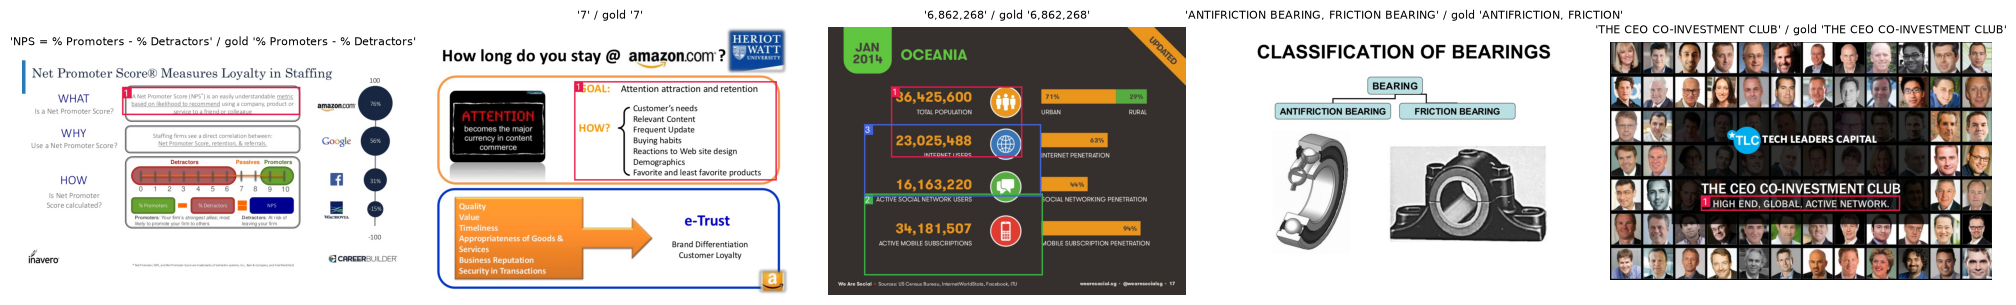

In [4]:
SMOKE = DEV[:5]
fig, axes = plt.subplots(1, len(SMOKE), figsize=(4 * len(SMOKE), 3))
for ax, it in zip(np.atleast_1d(axes), SMOKE):
    im = Image.open(os.path.join(DATA_ROOT, it['image'])).convert('RGB')
    rec = agent.run(im, it['question'], 'D')
    rec['id'], rec['gold'] = it['id'], it['answers']
    shown, gallery, log = demo.explain(im, rec)
    print(it['id'], '|', it['question'])
    print(log)
    print()
    ax.imshow(shown)
    ax.axis('off')
    ax.set_title(f"{rec['answer']!r} / gold {it['answers'][0]!r}", fontsize=8)
plt.tight_layout()
plt.show()

> **Result:** in the four cases where the model zoomed, the box sits on the region the question asks about, so the coordinates are read correctly: 0 to 1000, origin in the top-left corner. Exact match gives 3 of 5. The two misses are wording: `NPS = % Promoters - % Detractors` against the gold `% Promoters - % Detractors`, and `ANTIFRICTION BEARING, FRICTION BEARING` against `ANTIFRICTION, FRICTION`. One question took three zooms and 7211 tokens (38 s). In the last cell the expected 252 visual tokens agree with the backend's total of 309 for image, text and output.

In [5]:
im = Image.open(os.path.join(DATA_ROOT, SMOKE[0]['image'])).convert('RGB')
rec = agent.run(im, SMOKE[0]['question'], 'A')
print('expected visual tokens:', tools.visual_tokens(tools.fit(im, agent.CFG['low'])), '| tokens reported by backend (visual + text + output):', rec['tokens'])

expected visual tokens: 252 | tokens reported by backend (visual + text + output): 309


---

## 4. Runs: six viewing modes on 120 test questions

Every mode answers every question. Each answer is appended to a jsonl file as soon as it is finished and finished ids are skipped on restart, so any cell can be interrupted and run again. Dev is for checking prompts and code; test gives all reported numbers.

In [6]:
for m in 'ABCDEF':
    agent.run_dataset(DEV, m, f'{RESULTS}/{TAG}_dev.jsonl', root=DATA_ROOT)

In [7]:
for m in 'ABCDEF':
    agent.run_dataset(TEST, m, f'{RESULTS}/{TAG}_test.jsonl', root=DATA_ROOT)

> **Result:** all six modes finished on dev and test, and the test runs have no JSON format errors (`format_errors` is 0 in 5.1).

### Overview-budget control runs

The agent's overview has 256 visual tokens. Two extra runs with 768 tokens test whether a better first look lets it catch up with B: mode D (agent) and mode A (same overview, no zoom). The second run separates the effect of zoom from the effect of a bigger overview. Each run writes to its own file, and the budget returns to 256 afterwards.


In [8]:
RUN_D768 = True
if RUN_D768:
    agent.CFG['low'] = 768
    try:
        agent.run_dataset(TEST, 'D', f'{RESULTS}/{TAG}_test_low768.jsonl', root=DATA_ROOT)
    finally:
        agent.CFG['low'] = 256

In [9]:
RUN_A768 = True
if RUN_A768:
    agent.CFG['low'] = 768
    try:
        agent.run_dataset(TEST, 'A', f'{RESULTS}/{TAG}_test_low768_A.jsonl', root=DATA_ROOT)
    finally:
        agent.CFG['low'] = 256

---

## 5. Results: accuracy, cost and where zoom helps

Exact match (EM) counts an answer as right only if it equals the gold answer after normalization (case, punctuation marks, articles, etc.); F1 gives partial credit for shared words. Intervals are 95% bootstrap intervals: the 120 questions are resampled 2000 times. Need to keep in mind that small differences are not proper results.

**Formulas.** $\hat y$ is the model answer, $Y$ the set of accepted gold answers, $\mathrm{norm}$ turns a text into a list of words. Precision $P_g$ and recall $R_g$ count the words shared by $\mathrm{norm}(\hat y)$ and $\mathrm{norm}(g)$, divided by the length of the answer and of the gold answer.

$$\mathrm{EM} = \mathbb{1}\big[\mathrm{norm}(\hat y) = \mathrm{norm}(g) \text{ for some } g \in Y\big], \qquad F_1 = \max_{g \in Y} \frac{2\,P_g R_g}{P_g + R_g}$$

The bootstrap resamples the $n$ per-question scores with replacement 2000 times and takes the 2.5th and 97.5th percentile of the means. For an accuracy $p$ this is close to the normal interval, which gives the plus or minus 9 points quoted for 120 questions:

$$\pm\, 1.96\sqrt{\frac{p\,(1-p)}{n}}$$


### 5.1 Accuracy and cost by mode

In [10]:
RECS = {m: [r for r in agent.read_jsonl(f'{RESULTS}/{TAG}_test.jsonl') if r['mode'] == m] for m in 'ABCDEF'}
SCORES = {m: metrics.score(r) for m, r in RECS.items() if r}
table = pd.DataFrame(SCORES).T
table['em (95% ci)'] = [f"{s['em']:.2f} {s['em_ci']}" for s in SCORES.values()]
table['f1 (95% ci)'] = [f"{s['f1']:.2f} {s['f1_ci']}" for s in SCORES.values()]
table[['n', 'em (95% ci)', 'f1 (95% ci)', 'zoom_rate', 'mean_zooms', 'format_errors', 'tokens', 'seconds', 'num_5pct']]

,n,em (95% ci),f1 (95% ci),zoom_rate,mean_zooms,format_errors,tokens,seconds,num_5pct
A,120,"0.66 [0.575, 0.7417]","0.73 [0.657, 0.8039]",0.0,0.0,0.0,309.4,1.55,0.7969
B,120,"0.82 [0.75, 0.8833]","0.86 [0.8015, 0.914]",0.0,0.0,0.0,1583.5,10.89,0.8571
C,120,"0.75 [0.6667, 0.825]","0.83 [0.7645, 0.8881]",0.0,0.0,0.0,5003.2,36.64,0.9016
D,120,"0.66 [0.575, 0.7417]","0.74 [0.6651, 0.8094]",0.8417,0.91,0.0,1770.4,12.78,0.8361
E,120,"0.63 [0.55, 0.7167]","0.74 [0.6727, 0.8062]",0.9917,0.99,0.0,1737.4,11.71,0.85
F,120,"0.66 [0.575, 0.7417]","0.72 [0.647, 0.7993]",0.0,0.0,0.0,335.9,2.08,0.8226


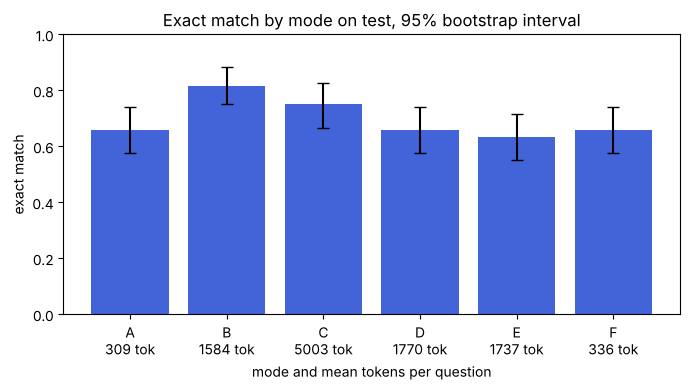

In [11]:
modes = list(SCORES)
em_m = [SCORES[m]['em'] for m in modes]
err = [[SCORES[m]['em'] - SCORES[m]['em_ci'][0] for m in modes], [SCORES[m]['em_ci'][1] - SCORES[m]['em'] for m in modes]]
labels = [f"{m}\n{SCORES[m]['tokens']:.0f} tok" for m in modes]
plt.figure(figsize=(7, 4))
plt.bar(labels, em_m, yerr=err, capsize=4, color='#4363d8')
plt.ylim(0, 1)
plt.ylabel('exact match')
plt.xlabel('mode and mean tokens per question')
plt.title('Exact match by mode on test, 95% bootstrap interval')
plt.tight_layout()
plt.show()

> **Results:** B, the whole slide at 1500 tokens, is the most accurate (EM 0.82 against 0.66 for A). The agent (D) equals A and F at 0.66 but costs 1770 tokens per question against 309 and 336, and 12.8 s against 1.6 s and 2.1 s. E, the forced single box, scores 0.63. D asks for a zoom on 84% of the questions and E, by design, on 99%. C reaches 0.75 and needs about 5000 tokens per question.

### 5.2 Paired comparisons between modes

Same questions, two modes: a bootstrap interval for the difference in EM and F1 and an exact McNemar test on EM, which looks only at questions where the two modes disagree. A to F shows whether the answer format matters; F to D is the effect of zoom at the same format.

**Formulas.** The interval is for the mean paired difference $\bar d$, where $a_i$ and $b_i$ are the scores of the two modes on question $i$. Let $x$ be the number of questions only the first mode gets right and $y$ the number only the second gets right. The exact McNemar test compares $x$ with a fair coin over $x + y$ flips:

$$\bar d = \frac{1}{n}\sum_{i=1}^{n} (b_i - a_i), \qquad p = 2\,\Pr\big[\mathrm{Bin}(x + y,\ \tfrac12) \le \min(x, y)\big]$$


In [12]:
PAIRS = [('A', 'B'), ('A', 'C'), ('A', 'D'), ('A', 'F'), ('F', 'D'), ('B', 'D'), ('C', 'D'), ('D', 'E')]
rows = []
for a, b in PAIRS:
    if RECS[a] and RECS[b]:
        rows.append({'pair': f'{a} -> {b}', **metrics.compare(RECS[a], RECS[b])})
pd.DataFrame(rows).set_index('pair')

,n,d_em,d_em_ci,d_f1,d_f1_ci,only_a,only_b,mcnemar_p
pair,,,,,,,,
A -> B,120,0.1583,"[0.0917, 0.225]",0.1290,"[0.0731, 0.191]",0,19,0.0000
A -> C,120,0.0917,"[0.025, 0.1583]",0.0998,"[0.0409, 0.1621]",3,14,0.0127
A -> D,120,0.0000,"[-0.0667, 0.0667]",0.0084,"[-0.0454, 0.0623]",8,8,1.0000
A -> F,120,0.0000,"[-0.0333, 0.0333]",-0.0060,"[-0.0283, 0.0112]",2,2,1.0000
F -> D,120,0.0000,"[-0.0583, 0.0583]",0.0144,"[-0.0392, 0.0704]",7,7,1.0000
B -> D,120,-0.1583,"[-0.225, -0.0917]",-0.1206,"[-0.1806, -0.0619]",20,1,0.0000
C -> D,120,-0.0917,"[-0.1667, -0.025]",-0.0915,"[-0.1535, -0.0308]",16,5,0.0266
D -> E,120,-0.0250,"[-0.0833, 0.0333]",0.0013,"[-0.0429, 0.0458]",8,5,0.5811


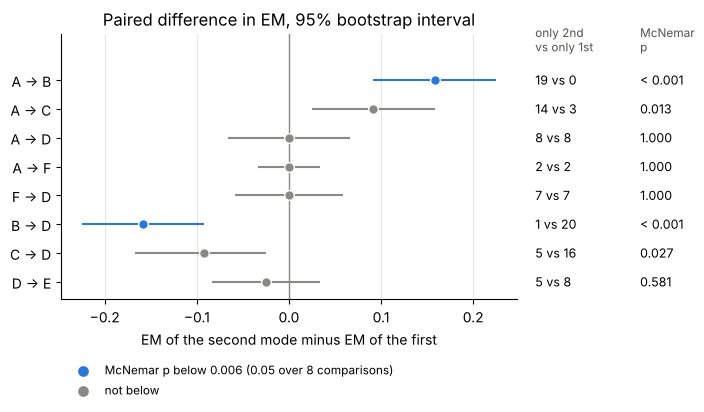

In [ ]:
PAIR_CMP = pd.DataFrame([{'pair': f'{a} -> {b}', **metrics.compare(RECS[a], RECS[b])} for a, b in PAIRS if RECS[a] and RECS[b]]).set_index('pair')
alpha = 0.05 / len(PAIRS)
fig, ax = plt.subplots(figsize=(8, 3.9))
ys = np.arange(len(PAIR_CMP))[::-1]
for y, (name, r) in zip(ys, PAIR_CMP.iterrows()):
    c = '#2a78d6' if r['mcnemar_p'] < alpha else '#8a8985'
    ax.errorbar(r['d_em'], y, xerr=[[r['d_em'] - r['d_em_ci'][0]], [r['d_em_ci'][1] - r['d_em']]], fmt='o', color=c, ecolor=c, elinewidth=1.5, markersize=7, markeredgecolor='white', zorder=3)
    p = '< 0.001' if r['mcnemar_p'] < 0.001 else f"{r['mcnemar_p']:.3f}"
    ax.text(1.04, y, f"{r['only_b']} vs {r['only_a']}", transform=ax.get_yaxis_transform(), va='center', fontsize=9)
    ax.text(1.27, y, p, transform=ax.get_yaxis_transform(), va='center', fontsize=9)
ax.text(1.04, ys[0] + 0.9, 'only 2nd\nvs only 1st', transform=ax.get_yaxis_transform(), va='bottom', fontsize=8.5, color='#52514e')
ax.text(1.27, ys[0] + 0.9, 'McNemar\np', transform=ax.get_yaxis_transform(), va='bottom', fontsize=8.5, color='#52514e')
ax.axvline(0, color='#8a8985', lw=1)
ax.set_yticks(ys)
ax.set_yticklabels(PAIR_CMP.index)
ax.set_ylim(-0.6, ys[0] + 1.6)
ax.set_xlabel('EM of the second mode minus EM of the first')
ax.set_title('Paired difference in EM, 95% bootstrap interval')
ax.scatter([], [], s=45, color='#2a78d6', label=f'McNemar p below {alpha:.3f} (0.05 over {len(PAIRS)} comparisons)')
ax.scatter([], [], s=45, color='#8a8985', label='not below')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(0, -0.2), fontsize=8.5)
ax.grid(axis='x', color='#e6e5e1', lw=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
fig.subplots_adjust(left=0.13, right=0.7, bottom=0.2)
plt.show()

> B beats A by 16 points (19 questions against 0). D against A or F is 0.00 with an interval of about plus or minus 6 points (8 against 8, 7 against 7), so no effect of zoom is detected, and the answer format does not matter (A against F: 2 against 2). D is 16 points below B at a similar cost. With eight comparisons a strict threshold is about p < 0.006, which only A to B and B to D clear.

### 5.3 Where zoom helps: answer type and zoom usage

EM by answer type for A, B, D and F, and D split by whether the model zoomed. The second split is not a causal estimate: the model chooses when to zoom, so the questions differ between the groups.

In [13]:
KIND = {it['id']: data.answer_kind(it) for it in ITEMS}
rows = []
for m in 'ABDF':
    for r in RECS[m]:
        rows.append({'mode': m, 'kind': KIND[r['id']], 'em': metrics.em(r['answer'], r['gold'])})
display(pd.DataFrame(rows).groupby(['kind', 'mode'])['em'].agg(['mean', 'count']).round(2))
used = {r['id']: metrics.valid_zooms(r) > 0 for r in RECS['D']}
a_em = {r['id']: metrics.em(r['answer'], r['gold']) for r in RECS['A']}
d_em = {r['id']: metrics.em(r['answer'], r['gold']) for r in RECS['D']}
display(pd.DataFrame([{'D zoomed': z, 'n': sum(1 for i in used if used[i] == z), 'em A': round(np.mean([a_em[i] for i in used if used[i] == z]), 2), 'em D': round(np.mean([d_em[i] for i in used if used[i] == z]), 2)} for z in (False, True) if any(v == z for v in used.values())]))

mean  count
kind   mode             
number A     0.75     60
       B     0.85     60
       D     0.70     60
       F     0.72     60
text   A     0.57     60
       B     0.78     60
       D     0.62     60
       F     0.60     60

,D zoomed,n,em A,em D
0,False,19,0.89,0.89
1,True,101,0.61,0.61


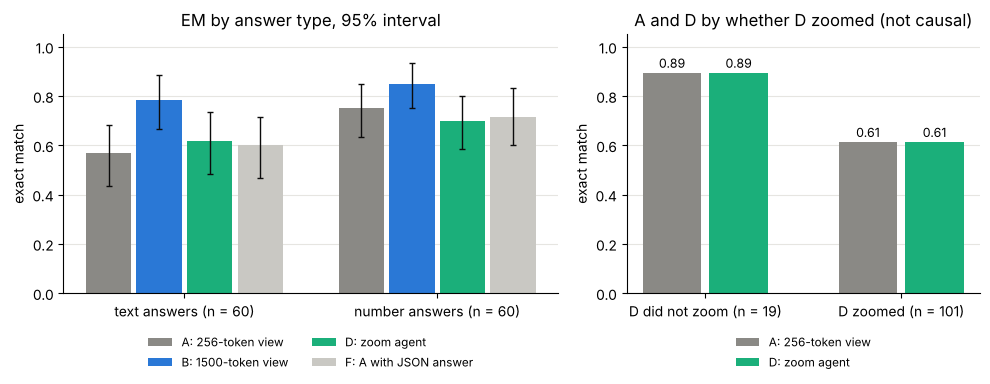

In [ ]:
COL = {'A': '#8a8985', 'B': '#2a78d6', 'D': '#1baf7a', 'F': '#c9c8c3'}
NAME = {'A': 'A: 256-token view', 'B': 'B: 1500-token view', 'D': 'D: zoom agent', 'F': 'F: A with JSON answer'}
kinds = ['text', 'number']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios': [1.4, 1]})
w = 0.2
for j, m in enumerate('ABDF'):
    for i, k in enumerate(kinds):
        s = [metrics.em(r['answer'], r['gold']) for r in RECS[m] if KIND[r['id']] == k]
        mean, (lo, hi) = metrics.ci(s)
        x = i + (j - 1.5) * w
        ax1.bar(x, mean, w * 0.9, color=COL[m], label=NAME[m] if i == 0 else None)
        ax1.errorbar(x, mean, yerr=[[mean - lo], [hi - mean]], color='#0b0b0b', lw=1, capsize=2.5)
ax1.set_xticks(range(len(kinds)))
ax1.set_xticklabels([f"{k} answers (n = {sum(1 for r in RECS['A'] if KIND[r['id']] == k)})" for k in kinds])
ax1.set_title('EM by answer type, 95% interval')
ax1.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
used = {r['id']: metrics.valid_zooms(r) > 0 for r in RECS['D']}
a_em = {r['id']: metrics.em(r['answer'], r['gold']) for r in RECS['A']}
d_em = {r['id']: metrics.em(r['answer'], r['gold']) for r in RECS['D']}
groups = [(False, 'D did not zoom'), (True, 'D zoomed')]
for i, (z, name) in enumerate(groups):
    ids = [k for k in used if used[k] == z]
    for j, (lab, src) in enumerate((('A', a_em), ('D', d_em))):
        v = float(np.mean([src[k] for k in ids]))
        x = i + (j - 0.5) * 0.34
        ax2.bar(x, v, 0.3, color=COL[lab], label=NAME[lab] if i == 0 else None)
        ax2.text(x, v + 0.02, f'{v:.2f}', ha='center', fontsize=9)
ax2.set_xticks(range(len(groups)))
ax2.set_xticklabels([f"{name} (n = {sum(1 for k in used if used[k] == z)})" for z, name in groups])
ax2.set_title('A and D by whether D zoomed (not causal)')
ax2.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=1)
for ax in (ax1, ax2):
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('exact match')
    ax.grid(axis='y', color='#e6e5e1', lw=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

> Text answers gain the most from a bigger view (B 0.78 against 0.57 for A), numbers less (0.85 against 0.75); each group has 60 questions, so intervals are about plus or minus 12 points. D does not zoom on 19 of 120 questions; on these A and D both reach 0.89, against 0.61 on the 101 zoomed ones. The model skips zoom mostly on easy questions.

### 5.4 Overview budget: 256 vs 768 tokens

Does a better first look let the agent catch up with B? D with a 768-token overview is compared with the same overview without zoom (A at 768), which separates the effect of zoom from the effect of a bigger overview.

In [14]:
R768 = agent.read_jsonl(f'{RESULTS}/{TAG}_test_low768.jsonl')
RA768 = agent.read_jsonl(f'{RESULTS}/{TAG}_test_low768_A.jsonl')
rows = {'A (256)': RECS['A'], 'A (768, no zoom)': RA768, 'D (overview 256)': RECS['D'], 'D (overview 768)': R768, 'B': RECS['B']}
sc = {k: metrics.score(v) for k, v in rows.items()}
t = pd.DataFrame(sc).T
t['em (95% ci)'] = [f"{s['em']:.2f} {s['em_ci']}" for s in sc.values()]
t['f1 (95% ci)'] = [f"{s['f1']:.2f} {s['f1_ci']}" for s in sc.values()]
display(t[['n', 'em (95% ci)', 'f1 (95% ci)', 'zoom_rate', 'mean_zooms', 'tokens', 'seconds']])
pairs = [('A (256)', 'A (768, no zoom)'), ('A (768, no zoom)', 'D (overview 768)'), ('D (overview 256)', 'D (overview 768)'), ('A (768, no zoom)', 'B'), ('B', 'D (overview 768)')]
display(pd.DataFrame([{'pair': f'{a} -> {b}', **metrics.compare(rows[a], rows[b])} for a, b in pairs]).set_index('pair'))

,n,em (95% ci),f1 (95% ci),zoom_rate,mean_zooms,tokens,seconds
A (256),120,"0.66 [0.575, 0.7417]","0.73 [0.657, 0.8039]",0.0,0.0,309.4,1.55
"A (768, no zoom)",120,"0.79 [0.7167, 0.8583]","0.87 [0.8135, 0.9188]",0.0,0.0,799.4,4.55
D (overview 256),120,"0.66 [0.575, 0.7417]","0.74 [0.6651, 0.8094]",0.8417,0.91,1770.4,12.78
D (overview 768),120,"0.71 [0.625, 0.7833]","0.80 [0.7344, 0.859]",0.8667,0.89,2664.3,18.51
B,120,"0.82 [0.75, 0.8833]","0.86 [0.8015, 0.914]",0.0,0.0,1583.5,10.89


,n,d_em,d_em_ci,d_f1,d_f1_ci,only_a,only_b,mcnemar_p
pair,,,,,,,,
"A (256) -> A (768, no zoom)",120,0.1333,"[0.075, 0.2]",0.1372,"[0.0824, 0.1964]",0,16,0.0000
"A (768, no zoom) -> D (overview 768)",120,-0.0833,"[-0.1417, -0.025]",-0.0675,"[-0.115, -0.0221]",12,2,0.0129
D (overview 256) -> D (overview 768),120,0.0500,"[0.0, 0.1]",0.0613,"[0.0135, 0.1111]",2,8,0.1094
"A (768, no zoom) -> B",120,0.0250,"[-0.0083, 0.0583]",-0.0082,"[-0.0351, 0.0189]",1,4,0.3750
B -> D (overview 768),120,-0.1083,"[-0.1667, -0.05]",-0.0593,"[-0.1087, -0.0125]",14,1,0.0010


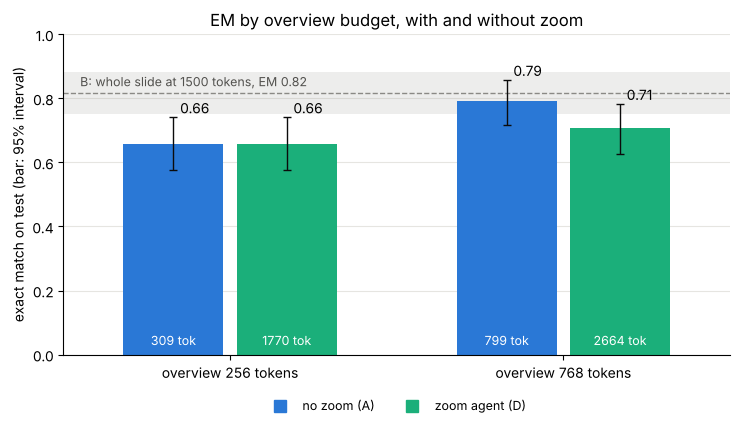

In [ ]:
groups = [('overview 256 tokens', 'A (256)', 'D (overview 256)'), ('overview 768 tokens', 'A (768, no zoom)', 'D (overview 768)')]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
b = sc['B']
ax.axhspan(b['em_ci'][0], b['em_ci'][1], color='#8a8985', alpha=0.15, lw=0)
ax.axhline(b['em'], color='#8a8985', ls='--', lw=1)
ax.text(-0.45, b['em'] + 0.012, f"B: whole slide at 1500 tokens, EM {b['em']:.2f}", fontsize=9, color='#52514e', va='bottom')
for i, (title, a_key, d_key) in enumerate(groups):
    for j, (key, c) in enumerate(((a_key, '#2a78d6'), (d_key, '#1baf7a'))):
        s = sc[key]
        x = i + (j - 0.5) * 0.34
        ax.bar(x, s['em'], 0.3, color=c)
        ax.errorbar(x, s['em'], yerr=[[s['em'] - s['em_ci'][0]], [s['em_ci'][1] - s['em']]], color='#0b0b0b', lw=1, capsize=3)
        ax.text(x, 0.03, f"{s['tokens']:.0f} tok", ha='center', color='white', fontsize=9)
        ax.text(x + 0.02, s['em_ci'][1] + 0.012, f"{s['em']:.2f}", ha='left', fontsize=10)
ax.plot([], [], 's', color='#2a78d6', ms=9, label='no zoom (A)')
ax.plot([], [], 's', color='#1baf7a', ms=9, label='zoom agent (D)')
ax.set_xticks(range(len(groups)))
ax.set_xticklabels([g[0] for g in groups])
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 1)
ax.set_ylabel('exact match on test (bar: 95% interval)')
ax.set_title('EM by overview budget, with and without zoom')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.1), fontsize=9, ncol=2)
ax.grid(axis='y', color='#e6e5e1', lw=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

> D with a 768-token overview reaches EM 0.71, 5 points above D at 256 tokens (interval 0 to +10). The same overview without zoom (A at 768 tokens) reaches 0.79 at about 800 tokens per question: 8 points above D at 768 (interval -14 to -3, 12 questions against 2) and within 3 points of B. A 1024x768 slide costs exactly 768 tokens at native resolution, so at this budget nothing is lost by downscaling and zoom has nothing to recover. Here zoom only adds cost and loses accuracy.

### 5.5 Accuracy against cost for all modes

Each point is one mode on the 120 test questions. The horizontal axis is the mean number of tokens per question (image, text and generated), the vertical axis is exact match, and the vertical bar is the 95% bootstrap interval. The dashed line joins the modes that no other mode beats at equal or lower cost.

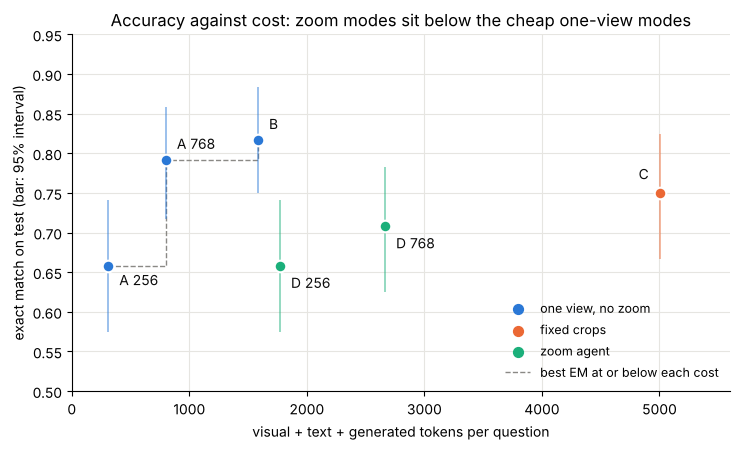

,family,tokens,em,lo,hi
mode,,,,,
A 256,"one view, no zoom",309.4,0.66,0.57,0.74
A 768,"one view, no zoom",799.4,0.79,0.72,0.86
B,"one view, no zoom",1583.5,0.82,0.75,0.88
C,fixed crops,5003.2,0.75,0.67,0.82
D 256,zoom agent,1770.4,0.66,0.57,0.74
D 768,zoom agent,2664.3,0.71,0.62,0.78


In [15]:
FRONT = [
    ('A 256', RECS['A'], 'one view, no zoom', (8, -14)),
    ('A 768', RA768, 'one view, no zoom', (8, 8)),
    ('B', RECS['B'], 'one view, no zoom', (8, 8)),
    ('C', RECS['C'], 'fixed crops', (-8, 10)),
    ('D 256', RECS['D'], 'zoom agent', (8, -16)),
    ('D 768', R768, 'zoom agent', (8, -16)),
]
FAMILY = {'one view, no zoom': '#2a78d6', 'fixed crops': '#eb6834', 'zoom agent': '#1baf7a'}
pts = []
for name, recs, fam, off in FRONT:
    s = metrics.score(recs)
    pts.append({'mode': name, 'family': fam, 'tokens': s['tokens'], 'em': s['em'], 'lo': s['em_ci'][0], 'hi': s['em_ci'][1], 'off': off})
frontier = [p for p in pts if not any(q['tokens'] <= p['tokens'] and q['em'] >= p['em'] and (q['tokens'], q['em']) != (p['tokens'], p['em']) for q in pts)]
frontier.sort(key=lambda p: p['tokens'])

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.step([p['tokens'] for p in frontier], [p['em'] for p in frontier], where='post', color='#8a8985', lw=1, ls='--', zorder=1)
for p in pts:
    c = FAMILY[p['family']]
    ax.errorbar(p['tokens'], p['em'], yerr=[[p['em'] - p['lo']], [p['hi'] - p['em']]], fmt='none', ecolor=c, elinewidth=1.2, alpha=0.55, capsize=0, zorder=2)
    ax.scatter(p['tokens'], p['em'], s=70, color=c, edgecolor='white', linewidth=1.5, zorder=3)
    ha = 'left' if p['off'][0] > 0 else 'right'
    ax.annotate(p['mode'], (p['tokens'], p['em']), xytext=p['off'], textcoords='offset points', ha=ha, fontsize=10, color='#0b0b0b')
for fam, c in FAMILY.items():
    ax.scatter([], [], s=50, color=c, label=fam)
ax.plot([], [], color='#8a8985', lw=1, ls='--', label='best EM at or below each cost')
ax.set_xlabel('visual + text + generated tokens per question')
ax.set_ylabel('exact match on test (bar: 95% interval)')
ax.set_ylim(0.5, 0.95)
ax.set_xlim(0, 5600)
ax.grid(color='#e6e5e1', lw=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc='lower right', fontsize=9)
ax.set_title('Accuracy against cost: zoom modes sit below the cheap one-view modes')
plt.tight_layout()
plt.show()
display(pd.DataFrame(pts).drop(columns='off').set_index('mode').round(2))

> Three modes lie on the dashed line: A at 256 tokens (EM 0.66, 309 tokens), A at 768 tokens (0.79, 799 tokens) and B (0.82, 1584 tokens). Going from 256 to 768 tokens buys 13 points for about 490 more tokens. Going from 768 to 1500 buys 2.5 more points for about 780 more tokens, and that gap is inside the noise (p = 0.375 in 5.4).

> Both agent runs sit below the line. D at 256 tokens costs 1770 tokens and scores 0.66, the same as A at 256, which costs 309. D at 768 costs 2664 tokens and scores 0.71, 8 points under A at 768. C, the fixed 2x2 tiles, costs 5003 tokens and reaches 0.75, no more than a single native-resolution view in this sample.

> The intervals overlap for most pairs, so the order inside the group A 768, B, C and D 768 is not established. The clear results are A at 256 below A at 768 and B, and D at 768 below A at 768. On SlideVQA, whose slides are 1024 px wide, a bigger single view is the cheapest way to gain accuracy and zoom is not on the efficient frontier.

---

## 6. Own questions

20 questions on course slides: 5 per detail type (axis label, value on a chart, small text, relation between blocks). Slide images are in `own_slides/` and the questions in `own_slides/questions.csv` (several accepted answers separated by `;`). The questions were written from the slides before any model run and not chosen by model errors.

> **Result (EM by detail type, 5 questions each, so one question moves a cell by 0.2):** A and F fail on axis labels (0.2 each) while B, C, D and E read them (1.0). Chart values are the weakest type for every mode (0.4 to 0.8). Block relations and small text are easy at this slide size (0.6 to 1.0).

In [16]:
OWN_CSV = data.make_own_template('own_slides/questions.csv')
OWN = data.load_own(OWN_CSV)
print(len(OWN), 'own questions filled')
if OWN:
    for m in 'ABCDEF':
        agent.run_dataset(OWN, m, f'{RESULTS}/{TAG}_own.jsonl', root='own_slides')
    own = [agent.read_jsonl(f'{RESULTS}/{TAG}_own.jsonl')]
    rows = [{'mode': r['mode'], 'type': next(o['detail_type'] for o in OWN if o['id'] == r['id']), 'em': metrics.em(r['answer'], r['gold'])} for r in own[0]]
    display(pd.DataFrame(rows).groupby(['type', 'mode'])['em'].mean().unstack().round(2))

20 own questions filled


mode,A,B,C,D,E,F
type,,,,,,
axis_label,0.2,1.0,1.0,1.0,1.0,0.2
block_relation,1.0,1.0,0.8,1.0,1.0,0.8
chart_value,0.6,0.8,0.4,0.8,0.6,0.4
small_text,1.0,1.0,0.8,0.8,0.6,0.8


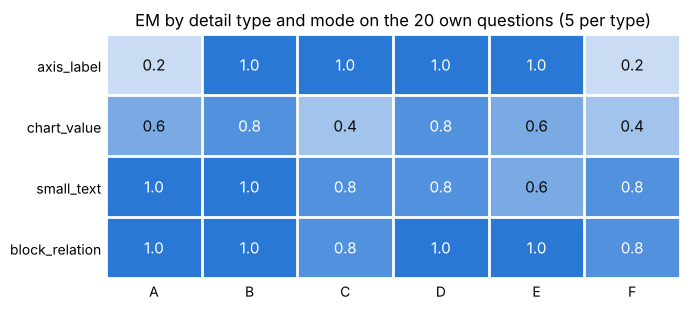

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
HEAT = LinearSegmentedColormap.from_list('heat', ['#f1f5fb', '#2a78d6'])
OWN_EM = pd.DataFrame(rows).groupby(['type', 'mode'])['em'].mean().unstack().loc[['axis_label', 'chart_value', 'small_text', 'block_relation']]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.imshow(OWN_EM.values, cmap=HEAT, vmin=0, vmax=1, aspect='auto')
for i in range(OWN_EM.shape[0]):
    for j in range(OWN_EM.shape[1]):
        v = OWN_EM.values[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', color='white' if v > 0.7 else '#0b0b0b', fontsize=11)
ax.set_xticks(range(OWN_EM.shape[1]))
ax.set_xticklabels(OWN_EM.columns)
ax.set_yticks(range(OWN_EM.shape[0]))
ax.set_yticklabels(OWN_EM.index)
ax.set_xticks(np.arange(-0.5, OWN_EM.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, OWN_EM.shape[0], 1), minor=True)
ax.grid(which='minor', color='white', lw=2)
ax.tick_params(which='both', length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title('EM by detail type and mode on the 20 own questions (5 per type)')
plt.tight_layout()
plt.show()

### 6.1 Own questions: a bigger overview without zoom

On the 20 own questions D (0.90) is close to B (0.95) and above A (0.70). A at 256 tokens is not the right rival for D, because D also gets 256 tokens for its overview and then spends more tokens on crops. A at 768 tokens costs about 800 tokens against about 1500 for D, and shows how much of D's gain a bigger first look explains. The budget returns to 256 after the run.

> **Result:** A at 768 tokens answers all 20 questions correctly (EM 1.00, 834 tokens), ahead of B (0.95, 1566 tokens) and D (0.90, 1494 tokens). With 20 questions the intervals are wide and the three modes are not separated. The result shows that a bigger first look matches the gain of D.

In [17]:
agent.CFG['low'] = 768
try:
    agent.run_dataset(OWN, 'A', f'{RESULTS}/{TAG}_own_low768_A.jsonl', root='own_slides')
finally:
    agent.CFG['low'] = 256

### 6.2 Dense slides: small text on a crowded slide

20 more questions on 8 slides where the answer sits in a table or chart of small print (multi-column tables, bar charts with value labels, a results table from a paper). Text height is roughly 1.4% of the slide height, so at B's size (1500 tokens, about 910 px for a 16:9 slide) a character is roughly 13 px high. This is the case where a full view should lose detail and a crop from the 2560 px original should help. The slides were chosen for density and the gold answers were checked against the slide text and the picture before any run; no question was chosen or dropped by a model result.

Modes A, A at 768 tokens, B, C and D run on all 20; E and F are skipped to save time (about 17 minutes in total on the 16 GB Mac).

> **Result (6.3):** A scores 0.55, A at 768 tokens 0.80, D 0.80, B 0.90 and C 0.95 on these 20 questions.

In [18]:
DENSE = data.load_own('own_slides/questions_dense.csv')
print(len(DENSE), 'dense questions')
for m in 'ABCD':
    agent.run_dataset(DENSE, m, f'{RESULTS}/{TAG}_dense.jsonl', root='own_slides')
agent.CFG['low'] = 768
try:
    agent.run_dataset(DENSE, 'A', f'{RESULTS}/{TAG}_dense_low768_A.jsonl', root='own_slides')
finally:
    agent.CFG['low'] = 256

20 dense questions


### 6.3 Own and dense questions together

EM with a 95% bootstrap interval, tokens and seconds per question, for the 20 own questions, the 20 dense questions and all 40. Then paired comparisons on the same questions (second mode minus first, exact McNemar test on EM) and EM by detail type and by slide on the dense set. With 20 to 40 questions an interval is about plus or minus 15 to 20 points, so only large gaps count.

In [19]:
def by_mode(path, modes):
    rs = agent.read_jsonl(path)
    return {m: [r for r in rs if r['mode'] == m] for m in modes}


ORDER = ['A', 'A768', 'B', 'C', 'D']
OWN_R = by_mode(f'{RESULTS}/{TAG}_own.jsonl', 'ABCDEF')
OWN_R['A768'] = by_mode(f'{RESULTS}/{TAG}_own_low768_A.jsonl', 'A')['A']
DENSE_R = by_mode(f'{RESULTS}/{TAG}_dense.jsonl', 'ABCD')
DENSE_R['A768'] = by_mode(f'{RESULTS}/{TAG}_dense_low768_A.jsonl', 'A')['A']
ALL_R = {m: OWN_R[m] + DENSE_R[m] for m in ORDER}
SETS = {'own 20': OWN_R, 'dense 20': DENSE_R, 'all 40': ALL_R}
rows = []
for name, R in SETS.items():
    for m in ORDER:
        s = metrics.score(R[m])
        rows.append({'set': name, 'mode': m, 'n': s['n'], 'em': round(s['em'], 2), 'em 95% ci': s['em_ci'], 'zoom_rate': round(s['zoom_rate'], 2), 'tokens': round(s['tokens']), 'seconds': round(s['seconds'], 1)})
display(pd.DataFrame(rows).set_index(['set', 'mode']))
PAIRS2 = [('A', 'D'), ('A768', 'D'), ('B', 'D'), ('A768', 'B'), ('A', 'A768')]
for name in ('dense 20', 'all 40'):
    print(name)
    display(pd.DataFrame([{'pair': f'{a} -> {b}', **metrics.compare(SETS[name][a], SETS[name][b])} for a, b in PAIRS2]).set_index('pair'))
TYPE = {o['id']: o['detail_type'] for o in DENSE}
IMG = {o['id']: o['image'] for o in DENSE}
rows = [{'mode': m, 'type': TYPE[r['id']], 'slide': IMG[r['id']], 'em': metrics.em(r['answer'], r['gold'])} for m in ORDER for r in DENSE_R[m]]
df = pd.DataFrame(rows)
display(df.groupby(['type', 'mode'])['em'].mean().unstack()[ORDER].round(2))
display(df.groupby(['slide', 'mode'])['em'].mean().unstack()[ORDER].round(2))

n    em       em 95% ci  zoom_rate  tokens  seconds
set      mode                                                      
own 20   A     20  0.70      [0.5, 0.9]       0.00     309      1.5
         A768  20  1.00      [1.0, 1.0]       0.00     834      4.2
         B     20  0.95     [0.85, 1.0]       0.00    1566      9.0
         C     20  0.75    [0.55, 0.95]       0.00    3932     25.2
         D     20  0.90     [0.75, 1.0]       0.95    1494      9.9
dense 20 A     20  0.55    [0.35, 0.75]       0.00     313      1.6
         A768  20  0.80     [0.6, 0.95]       0.00     838      5.2
         B     20  0.90     [0.75, 1.0]       0.00    1569      9.9
         C     20  0.95     [0.85, 1.0]       0.00    3928     25.3
         D     20  0.80     [0.6, 0.95]       0.95    1429      8.9
all 40   A     40  0.62  [0.475, 0.775]       0.00     311      1.6
         A768  40  0.90    [0.8, 0.975]       0.00     836      4.7
         B     40  0.93    [0.825, 1.0]       0.00    1567      9.4
         C     40  0.85   [0.725, 0.95]       0.00    3930     25.3
         D     40  0.85    [0.75, 0.95]       0.95    1462      9.4

dense 20


,n,d_em,d_em_ci,d_f1,d_f1_ci,only_a,only_b,mcnemar_p
pair,,,,,,,,
A -> D,20,0.25,"[0.0, 0.5]",0.2410,"[0.0103, 0.475]",2,7,0.1797
A768 -> D,20,0.00,"[-0.25, 0.25]",0.0071,"[-0.2127, 0.2518]",3,3,1.0000
B -> D,20,-0.10,"[-0.35, 0.15]",-0.0888,"[-0.2769, 0.0977]",4,2,0.6875
A768 -> B,20,0.10,"[-0.1, 0.3]",0.0958,"[-0.0208, 0.2625]",1,3,0.6250
A -> A768,20,0.25,"[0.0, 0.5]",0.2339,"[0.0213, 0.4625]",2,7,0.1797


all 40


,n,d_em,d_em_ci,d_f1,d_f1_ci,only_a,only_b,mcnemar_p
pair,,,,,,,,
A -> D,40,0.225,"[0.0494, 0.4]",0.1844,"[0.0313, 0.3308]",4,13,0.0490
A768 -> D,40,-0.050,"[-0.2, 0.075]",-0.0298,"[-0.1548, 0.0943]",5,3,0.7266
B -> D,40,-0.075,"[-0.2, 0.05]",-0.0527,"[-0.1445, 0.0363]",5,2,0.4531
A768 -> B,40,0.025,"[-0.075, 0.125]",0.0229,"[-0.0667, 0.1126]",2,3,1.0000
A -> A768,40,0.275,"[0.1, 0.45]",0.2142,"[0.0795, 0.3538]",2,13,0.0074


mode,A,A768,B,C,D
type,,,,,
axis_label,0.50,1.00,1.00,1.00,1.00
chart_value,0.33,0.33,0.67,1.00,0.67
small_text,0.60,0.87,0.93,0.93,0.80


mode,A,A768,B,C,D
slide,,,,,
d_l2_p33.png,0.50,1.00,1.00,1.00,0.50
d_l2_p38.png,1.00,1.00,1.00,1.00,1.00
d_l3_p16.png,0.50,1.00,1.00,1.00,0.50
d_l3_p29.png,0.67,0.67,0.67,0.67,0.67
d_l5_p04.png,0.50,1.00,1.00,1.00,1.00
d_vw_p58.png,0.33,0.67,1.00,1.00,1.00
d_vw_p82.png,0.50,1.00,1.00,1.00,0.50
d_vw_p83.png,0.33,0.33,0.67,1.00,1.00


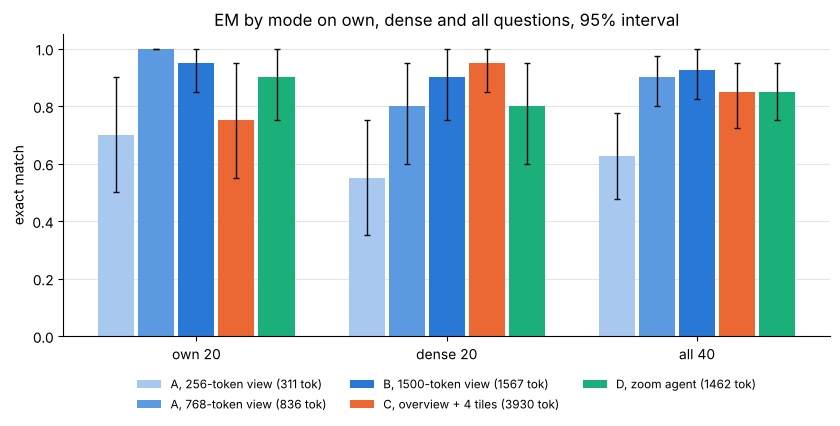

In [ ]:
STYLE = {'A': ('A, 256-token view', '#a9c8ef'), 'A768': ('A, 768-token view', '#5b9ae0'), 'B': ('B, 1500-token view', '#2a78d6'), 'C': ('C, overview + 4 tiles', '#eb6834'), 'D': ('D, zoom agent', '#1baf7a')}
fig, ax = plt.subplots(figsize=(8.5, 4.4))
w = 0.16
for j, m in enumerate(ORDER):
    label, c = STYLE[m]
    tok = metrics.score(ALL_R[m])['tokens']
    for i, (name, R) in enumerate(SETS.items()):
        s = metrics.score(R[m])
        x = i + (j - 2) * w
        ax.bar(x, s['em'], w * 0.9, color=c, label=f'{label} ({tok:.0f} tok)' if i == 0 else None)
        ax.errorbar(x, s['em'], yerr=[[s['em'] - s['em_ci'][0]], [s['em_ci'][1] - s['em']]], color='#0b0b0b', lw=1, capsize=2.5)
ax.set_xticks(range(len(SETS)))
ax.set_xticklabels(list(SETS))
ax.set_ylim(0, 1.05)
ax.set_ylabel('exact match')
ax.set_title('EM by mode on own, dense and all questions, 95% interval')
ax.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
ax.grid(axis='y', color='#e6e5e1', lw=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

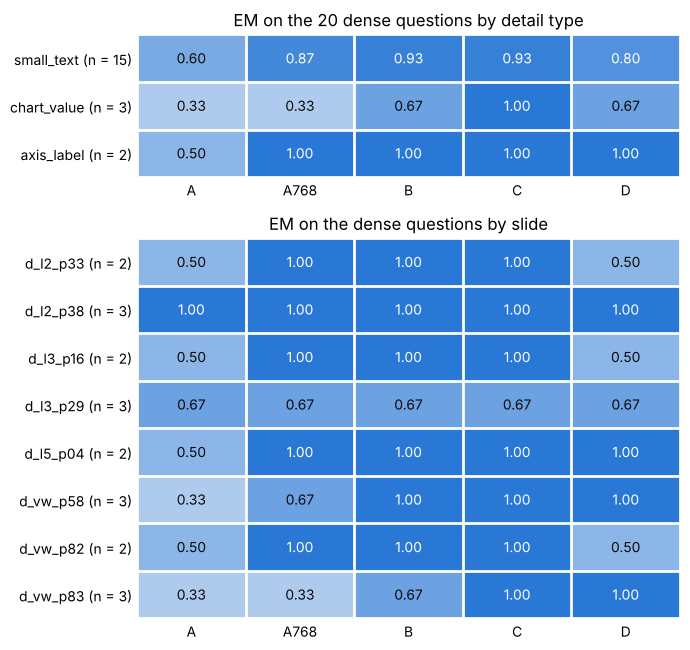

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
HEAT = LinearSegmentedColormap.from_list('heat', ['#f1f5fb', '#2a78d6'])


def heat(ax, M, labels, title):
    ax.imshow(M.values, cmap=HEAT, vmin=0, vmax=1, aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v > 0.7 else '#0b0b0b', fontsize=10)
    ax.set_xticks(range(M.shape[1]))
    ax.set_xticklabels(M.columns)
    ax.set_yticks(range(M.shape[0]))
    ax.set_yticklabels(labels)
    ax.set_xticks(np.arange(-0.5, M.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, M.shape[0], 1), minor=True)
    ax.grid(which='minor', color='white', lw=2)
    ax.tick_params(which='both', length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_title(title)


n_type = df[df['mode'] == 'A'].groupby('type').size()
n_slide = df[df['mode'] == 'A'].groupby('slide').size()
TYPE_EM = df.groupby(['type', 'mode'])['em'].mean().unstack()[ORDER].loc[['small_text', 'chart_value', 'axis_label']]
SLIDE_EM = df.groupby(['slide', 'mode'])['em'].mean().unstack()[ORDER]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6.6), gridspec_kw={'height_ratios': [3, 8]})
heat(ax1, TYPE_EM, [f'{t} (n = {n_type[t]})' for t in TYPE_EM.index], 'EM on the 20 dense questions by detail type')
heat(ax2, SLIDE_EM, [f"{s.replace('.png', '')} (n = {n_slide[s]})" for s in SLIDE_EM.index], 'EM on the dense questions by slide')
plt.tight_layout()
plt.show()

> On the 40 own and dense questions D (0.85) is 22.5 points above A (13 questions against 4, p = 0.049). It is 5 points below A at 768 tokens (0.90, 5 against 3) and 7.5 points below B (0.93, 5 against 2); both gaps are inside the noise. A at 768 tokens beats A at 256 by 27.5 points (13 against 2, p = 0.007), the clearest effect in this section.

> On the 20 dense questions the fixed tiles of C score highest (0.95, 3928 tokens), ahead of B (0.90) and of D and A at 768 tokens (0.80 each), but the intervals overlap. By detail type, small text (15 questions) rises from 0.60 for A to 0.93 for B and C, and chart values (3 questions) are the hardest (A 0.33, D 0.67, C 1.00). D scores 0.50 on three slides where A at 768 tokens and B score 1.00 (`d_l2_p33`, `d_l3_p16`, `d_vw_p82`). The cells are tiny, 2 or 3 questions per type and slide, so they show where to look in section 7 and prove nothing.

---

## 7. Error analysis

The table has the errors of mode D and of mode A (30 each, sampled with a fixed seed from the 41 errors each mode makes on test). For every error there is a montage image: the slide with numbered boxes and the crops the model saw. The `category` column holds the cause assigned from the montage and the `note` column gives the reason. Categories:

| Category | Meaning |
|---|---|
| `no_zoom` | the needed text was too small to read at the overview size |
| `wrong_region` | the box is not on the evidence, or it cuts off part of it |
| `misread` | right region, text read wrongly |
| `format` | correct in meaning but exact match fails (counted separately as a metric error) |
| `reasoning` | the evidence is visible and the answer needs a comparison, a count or a link between blocks |
| `bad_gold` | the gold label or the evidence slide looks wrong |

`f1` and `num_5pct` are hints for `format` only.

In [20]:
def error_rows(mode, k=30, seed=0):
    wrong = [r for r in RECS[mode] if metrics.em(r['answer'], r['gold']) == 0]
    random.Random(seed).shuffle(wrong)
    out = []
    for r in wrong[:k]:
        it = next(x for x in ITEMS if x['id'] == r['id'])
        im = Image.open(os.path.join(DATA_ROOT, it['image'])).convert('RGB')
        path = demo.montage(im, r, f'errors/{TAG}_{mode}_{r["id"]}.png')
        out.append({'id': r['id'], 'mode': mode, 'question': r['question'], 'gold': ' | '.join(r['gold']), 'answer': r['answer'], 'boxes': json.dumps([s['box'] for s in r['steps'] if s['valid']]), 'montage': path, 'f1': metrics.f1(r['answer'], r['gold']), 'num_5pct': metrics.num_ok(r['answer'], r['gold']), 'category': ''})
    return out


ERR_CSV = f'errors/{TAG}_error_table.csv'
if os.path.exists(ERR_CSV):
    print(ERR_CSV, 'exists, not overwritten (it may hold hand-filled categories)')
else:
    os.makedirs('errors', exist_ok=True)
    pd.DataFrame(error_rows('D') + error_rows('A')).to_csv(ERR_CSV, index=False)
pd.read_csv(ERR_CSV).head(10)

errors/mlx_error_table.csv exists, not overwritten (it may hold hand-filled categories)


,id,mode,question,gold,answer,boxes,montage,f1,num_5pct,category,note
0,544,D,"Volume, Velocity, Variety, and Veracity are pa...",Value,The 4 V's of Big Data,"[[528.0, 166.0, 945.0, 552.0]]",errors/mlx_D_544.png,0.0000,0.0,reasoning,right region; gold Value is the centre of the ...
1,938,D,For which key element do Commerce Bank and Cit...,PC banking,Branch Hours,"[[62.0, 622.0, 962.0, 962.0]]",errors/mlx_D_938.png,0.0000,NaN,wrong_region,"box covers only the x-axis labels, not the two..."
2,53,D,How many points are listed to explain that A g...,7,6,"[[222.0, 148.0, 978.0, 786.0]]",errors/mlx_D_53.png,0.0000,0.0,reasoning,whole diagram in the box; counted 6 of 7 boxes
3,281,D,What is the average session duration for desktop?,00:04:14,00:03:51,"[[855.0, 386.0, 947.0, 444.0]]",errors/mlx_D_281.png,0.3333,1.0,wrong_region,"box on the total row (03:51), question asks fo..."
4,101,D,What is Hilton Sydney's star rating?,3.9,Not visible,"[[12.0, 422.0, 156.0, 478.0]]",errors/mlx_D_101.png,0.0000,NaN,wrong_region,box on the hotel name; the 3.9 rating is at th...
5,912,D,Which is the most expensive of Aqualisa's Core...,Aquavalve 609,Premium,"[[672.0, 259.0, 906.0, 328.0]]",errors/mlx_D_912.png,0.0000,NaN,wrong_region,box on the column header only; prices are in t...
6,1018,D,What part of the esophagus is just above the c...,Lower thoracic esophagus,Lower 1/3 (Distal),"[[322.0, 786.0, 582.0, 937.0]]",errors/mlx_D_1018.png,0.2857,0.0,format,same segment named on the other scale (Lower 1...
7,870,D,What three types of brick are pictured in the ...,"American, ROMAN, ENGLiSH","American Brick, Roman Brick, English Brick","[[238.0, 500.0, 823.0, 875.0]]",errors/mlx_D_870.png,0.6667,NaN,format,"right three types, extra word Brick"
8,1000,D,Salespeople with how many years experience get...,2-5,2-5 years,"[[166.0, 388.0, 922.0, 584.0]]",errors/mlx_D_1000.png,0.8000,1.0,format,"right row, extra word years"
9,41,D,Which part of appendixes shows the Signs/sympt...,Retro/paraileal,Retro/parailael,"[[57.0, 610.0, 572.0, 708.0]]",errors/mlx_D_41.png,0.5000,NaN,misread,"right cell, answer misspelled (parailael)"


Cases where A and D disagree on exact match. `zoom_helped` is 1 when D is right and A is wrong. These are the most informative cases for the analysis; fill `category` by hand here too.

> **Result:** A and D disagree on 16 of the 120 test questions, 8 in each direction (p = 1.0). D is right and A wrong on 8: 6 times A could not read small text, once it misread, once it fails on format. A is right and D wrong on 8: 5 wrong boxes, 2 format mismatches and 1 reasoning case. Zoom fixes what A cannot read and loses about as many questions where the box misses the evidence.

In [21]:
def discordant(a='A', b='D'):
    ra, rb = ({r['id']: r for r in RECS[m]} for m in (a, b))
    out = []
    for i in sorted(set(ra) & set(rb)):
        ok_a, ok_b = metrics.em(ra[i]['answer'], ra[i]['gold']), metrics.em(rb[i]['answer'], rb[i]['gold'])
        if ok_a != ok_b:
            it = next(x for x in ITEMS if x['id'] == i)
            im = Image.open(os.path.join(DATA_ROOT, it['image'])).convert('RGB')
            path = demo.montage(im, rb[i], f'errors/{TAG}_disc_{i}.png')
            out.append({'id': i, 'zoom_helped': int(ok_b > ok_a), 'question': rb[i]['question'], 'gold': ' | '.join(rb[i]['gold']), 'answer_A': ra[i]['answer'], 'answer_D': rb[i]['answer'], 'boxes': json.dumps([s['box'] for s in rb[i]['steps'] if s['valid']]), 'montage': path, 'category': ''})
    return out


DISC_CSV = f'errors/{TAG}_discordant.csv'
if os.path.exists(DISC_CSV):
    print(DISC_CSV, 'exists, not overwritten')
else:
    os.makedirs('errors', exist_ok=True)
    pd.DataFrame(discordant()).to_csv(DISC_CSV, index=False)
pd.read_csv(DISC_CSV)[['id', 'zoom_helped', 'question', 'gold', 'answer_A', 'answer_D']]

errors/mlx_discordant.csv exists, not overwritten


,id,zoom_helped,question,gold,answer_A,answer_D
0,205,1,What types of infrastructures exist in the Mob...,"Carriers, Cloud, Video","(Carrier, Cloud, Video)","Carriers, Cloud, Video"
1,281,0,What is the average session duration for desktop?,00:04:14,00:04:14,00:03:51
2,32,1,What is the abbreviation for Sales Qualified L...,SQL,SAL,SQL
3,38,1,In which year may Subnational Debts be relieve...,2015,2016,2015
4,448,0,How many subscribers does Mahindra e2o's YouTu...,108,108,"236,483"
5,486,1,What percentage of base oil is made up of addi...,15-25,25%,15-25%
6,489,0,"Between 2010 and 2020, Internet penetration in...",37,37,62%
7,618,1,Were there more farmers in 2001 or 2002?,2001,2002,2001
8,648,1,Whose name is selected in the image showing th...,Ben Borthwick,John Johnston,Ben Borthwick
9,666,0,Which chapter of the BEPS Action Plan is the q...,3,3,chapter 3


In [22]:
FD_CSV = f'errors/{TAG}_discordant_FD.csv'
if os.path.exists(FD_CSV):
    print(FD_CSV, 'exists, not overwritten')
else:
    pd.DataFrame(discordant('F', 'D')).to_csv(FD_CSV, index=False)
pd.read_csv(FD_CSV)[['id', 'zoom_helped', 'question', 'gold', 'answer_A', 'answer_D']]

errors/mlx_discordant_FD.csv exists, not overwritten


,id,zoom_helped,question,gold,answer_A,answer_D
0,117,1,What percentage of Users have an average Sessi...,50,100%,50%
1,281,0,What is the average session duration for desktop?,00:04:14,00:04:14,00:03:51
2,32,1,What is the abbreviation for Sales Qualified L...,SQL,SAL,SQL
3,38,1,In which year may Subnational Debts be relieve...,2015,2016,2015
4,448,0,How many subscribers does Mahindra e2o's YouTu...,108,108,"236,483"
5,486,1,What percentage of base oil is made up of addi...,15-25,25%,15-25%
6,489,0,"Between 2010 and 2020, Internet penetration in...",37,37,62%
7,618,1,Were there more farmers in 2001 or 2002?,2001,2002,2001
8,648,1,Whose name is selected in the image showing th...,Ben Borthwick,John Johnston,Ben Borthwick
9,679,0,About how many positions in Europe are affecte...,400,400,About 400 positions in Europe are affected


### Errors of D on the own and dense questions

D makes 2 errors on the 20 own questions and 4 on the 20 dense ones. All six are in `errors/mlx_own_dense_D.csv` with the same kind of montage image. The set is small enough to list in full, so there is no sampling here. Categories were assigned by hand from the montages; the `note` column gives the reason for each row.

> **Result:** the two errors on own questions are one reasoning case (`own_10`) and one format mismatch (`own_11`). On the dense slides three errors are wrong boxes (`dense_01`, `dense_08`, `dense_10`) and one is a wrong bar read inside the right box (`dense_14`, labelled `reasoning`).

In [23]:
def own_dense_rows():
    items = {o['id']: o for o in OWN + DENSE}
    out = []
    for name, recs in (('own', OWN_R['D']), ('dense', DENSE_R['D'])):
        for r in recs:
            if metrics.em(r['answer'], r['gold']):
                continue
            it = items[r['id']]
            im = Image.open(os.path.join('own_slides', it['image'])).convert('RGB')
            path = demo.montage(im, r, f'errors/{TAG}_ownD_{r["id"]}.png')
            out.append({'id': r['id'], 'set': name, 'image': it['image'], 'detail_type': it['detail_type'], 'question': r['question'], 'gold': ' | '.join(r['gold']), 'answer': r['answer'], 'boxes': json.dumps([s['box'] for s in r['steps'] if s['valid']]), 'montage': path, 'f1': metrics.f1(r['answer'], r['gold']), 'category': ''})
    return out


OD_CSV = f'errors/{TAG}_own_dense_D.csv'
if os.path.exists(OD_CSV):
    print(OD_CSV, 'exists, not overwritten')
else:
    pd.DataFrame(own_dense_rows()).to_csv(OD_CSV, index=False)
pd.read_csv(OD_CSV)[['id', 'set', 'question', 'gold', 'answer', 'category']]

errors/mlx_own_dense_D.csv exists, not overwritten


,id,set,question,gold,answer,category
0,own_10,own,Which y-axis tick label lies between 3.0 and 2.0?,2.5,Test loss (log scale),reasoning
1,own_11,own,"According to the figure caption, how many time...",16 | 16x,16x faster,format
2,dense_01,dense,What attention share of sequence mixers is lis...,6 of 29 | 6 of 29 (≈ 21%) | 6 of 29 (21%),1 of 8 (12.5%),wrong_region
3,dense_08,dense,What model size is listed for Llama 2 (2023)?,7B – 70B dense | 7B-70B dense,1–32B dense for on-device use; 100B–1T MoE wit...,wrong_region
4,dense_10,dense,"Where is Gated DeltaNet used, according to the...","Qwen3-Next, Qwen3.5",Qwen3.5,wrong_region
5,dense_14,dense,What value is shown for DreamZero (Scratch) on...,93.8,2.1,reasoning


### Error categories of A and D on the test set

Counts and shares of the hand-labelled categories in `errors/mlx_error_table.csv` (30 sampled errors per mode out of all errors of that mode on test), and the same shares scaled to the full number of errors of the mode. The scaled counts are estimates from a sample of 30.

**Formulas.** $k_c$ is the number of sampled errors in category $c$ (30 per mode) and $N_{\mathrm{err}} = n\,(1 - \mathrm{EM})$ the number of errors of the mode on test:

$$\text{share}_c = \frac{k_c}{30}, \qquad \hat N_c = N_{\mathrm{err}} \cdot \frac{k_c}{30}$$

| Category | Meaning |
|---|---|
| `format` | the answer is right in meaning and fails only the exact match; this share is a metric error. |
| `wrong_region` | the box is not on the evidence, or it cuts off part of it. A never zooms, so it has none. |
| `no_zoom` | the needed text was too small to read at the overview size (for D: no zoom was requested). |
| `misread` | right region, text read wrongly. |
| `reasoning` | the evidence is visible and the answer needs a comparison, a count or a link between blocks. |
| `bad_gold` | the gold label or the evidence slide looks wrong. |



In [24]:
CATS = ['format', 'wrong_region', 'reasoning', 'no_zoom', 'misread', 'bad_gold']
err = pd.read_csv(ERR_CSV)
n_err = pd.Series({m: sum(1 for r in RECS[m] if not metrics.em(r['answer'], r['gold'])) for m in 'AD'})
cnt = pd.crosstab(err['mode'], err['category']).reindex(columns=CATS, fill_value=0)
share = cnt.div(cnt.sum(axis=1), axis=0)
print('errors on test:', n_err.to_dict())
display(cnt)
display((share * 100).round(0))
display(share.mul(n_err, axis=0).round(1))

errors on test: {'A': 41, 'D': 41}


category,format,wrong_region,reasoning,no_zoom,misread,bad_gold
mode,,,,,,
A,8,0,5,12,3,2
D,10,10,6,1,2,1


category,format,wrong_region,reasoning,no_zoom,misread,bad_gold
mode,,,,,,
A,27.0,0.0,17.0,40.0,10.0,7.0
D,33.0,33.0,20.0,3.0,7.0,3.0


category,format,wrong_region,reasoning,no_zoom,misread,bad_gold
mode,,,,,,
A,10.9,0.0,6.8,16.4,4.1,2.7
D,13.7,13.7,8.2,1.4,2.7,1.4


> Of the 30 sampled errors of D, 10 are `format`, 10 `wrong_region`, 6 `reasoning`, 2 `misread`, 1 `no_zoom` and 1 `bad_gold`. Scaled to its 41 errors on test, D has about 14 wrong boxes and about 14 format mismatches, a third of its errors each. Of the 30 sampled errors of A, 12 are `no_zoom` (about 16 after scaling), 8 `format`, 5 `reasoning`, 3 `misread` and 2 `bad_gold`.

> Zoom removes most of the `no_zoom` errors (1 left against 12) and adds `wrong_region` errors (10 against 0). That is why D and A both make 41 errors. About a third of the errors of D and a quarter of those of A are `format`, so exact match understates both modes. The shares come from samples of 30, so each count is uncertain by several errors. The categories were assigned in one pass by an AI assistant and checked by one of the authors.

---

## 8. Demo

> Pick a slide or upload one, type a question, choose a mode and see the answer, the slide with numbered boxes, the gallery of crops and the step log. The Replay tab shows precomputed mode D records from the test run, since the live model is slow.


In [25]:
try:
    app = demo.build_app(TEST, DATA_ROOT, backend=BACKEND, replay_path=f'{RESULTS}/{TAG}_test.jsonl')
    app.launch(inline=True, prevent_thread_lock=True)
except ImportError:
    print('gradio is not installed: pip install gradio')

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


---

## 9. Limitations

- Model we set on is the smaller one due to computing limitations.
- SlideVQA images in the Hugging Face release have a longest side of 1024 px, Zoom therefore gets small reveal detail beyond 1024 px; its gain over the overview comes from the 1024 px original versus a 256-token overview, and from more tokens per region.
- Modes A to C use a text answer prompt and D, E use JSON, so part of a gap can come from the prompt format.
- A visual token is taken as 32x32 pixels, and the budgets are enforced by resizing before the model call. The low budget is 256 tokens and the high budget 1500 tokens.
- Zoom crops are upsampled from the original. If slide images are small, part of the zoom gain is plain upsampling, which mode B tests.
- EM penalises correct answers in another format (units, "12.5 bn" and "12.5").
- The 40 own and dense questions were written by us on 17 slides. The dense slides were chosen for small print, which favours any method that reads small print.